In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report,confusion_matrix
from joblib import dump


In [3]:
df = pd.read_excel("../Datasets/COPD_Prediction_Dataset.xlsx")
df

,Age,Gender,BMI,Smoking_Status,Pack_Years,Secondhand_Smoke_Exposure,Occupational_Dust_Exposure,Air_Pollution_Exposure,Family_History_COPD,Asthma,Hypertension,Diabetes,Chronic_Cough,Sputum_Production,Wheezing,Shortness_of_Breath,Oxygen_Saturation,Physical_Activity,FEV1_Percent_Predicted,COPD
0,85,Male,17.4,Former,34,Yes,Yes,High,Yes,No,Yes,Yes,Yes,Yes,Yes,Severe,94,Low,47.5,1
1,62,Male,29.9,Former,47,No,No,Moderate,No,Yes,Yes,No,Yes,Yes,Yes,Moderate,87,High,43.9,1
2,80,Female,31.1,Current,75,No,Yes,High,Yes,No,No,No,No,No,Yes,Moderate,91,Low,42.8,1
3,87,Female,28.9,Current,24,Yes,Yes,Moderate,No,Yes,No,No,Yes,Yes,No,Mild,86,Moderate,45.1,1
4,49,Male,32.5,Current,65,No,Yes,High,No,No,No,Yes,Yes,No,Yes,Severe,92,Moderate,45.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,31,Female,35.8,Never,15,No,Yes,Low,Yes,No,Yes,No,No,No,No,NaN,99,Low,115.6,0
49996,53,Male,32.7,Never,30,Yes,No,Moderate,No,No,No,No,No,Yes,No,NaN,96,Low,110.4,0
49997,55,Female,30.0,Never,19,Yes,No,High,No,No,No,No,No,No,No,Mild,99,High,92.0,0
49998,72,Male,30.8,Never,2,No,No,Moderate,No,No,No,No,No,No,No,Moderate,99,High,113.4,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         50000 non-null  int64  
 1   Gender                      50000 non-null  object 
 2   BMI                         50000 non-null  float64
 3   Smoking_Status              50000 non-null  object 
 4   Pack_Years                  50000 non-null  int64  
 5   Secondhand_Smoke_Exposure   50000 non-null  object 
 6   Occupational_Dust_Exposure  50000 non-null  object 
 7   Air_Pollution_Exposure      50000 non-null  object 
 8   Family_History_COPD         50000 non-null  object 
 9   Asthma                      50000 non-null  object 
 10  Hypertension                50000 non-null  object 
 11  Diabetes                    50000 non-null  object 
 12  Chronic_Cough               50000 non-null  object 
 13  Sputum_Production           500

In [5]:
df.isna().sum() / len(df)  * 100

Age                            0.00
Gender                         0.00
BMI                            0.00
Smoking_Status                 0.00
Pack_Years                     0.00
Secondhand_Smoke_Exposure      0.00
Occupational_Dust_Exposure     0.00
Air_Pollution_Exposure         0.00
Family_History_COPD            0.00
Asthma                         0.00
Hypertension                   0.00
Diabetes                       0.00
Chronic_Cough                  0.00
Sputum_Production              0.00
Wheezing                       0.00
Shortness_of_Breath           36.42
Oxygen_Saturation              0.00
Physical_Activity              0.00
FEV1_Percent_Predicted         0.00
COPD                           0.00
dtype: float64

In [6]:
for col in df.columns:
    print(df[col].unique(),col)
    print()

[85 62 80 87 49 59 78 55 48 67 63 50 64 82 56 70 84 45 60 51 72 54 83 81
 79 61 89 86 65 77 46 75 68 52 90 73 53 76 88 47 58 69 66 57 74 71 35 20
 32 37 19 18 27 34 25 26 41 29 40 30 39 43 23 21 22 28 42 31 33 38 24 44
 36] Age

['Male' 'Female'] Gender

[17.4 29.9 31.1 28.9 32.5 25.7 18.9 27.2 26.  18.1 24.  17.9 28.8 18.2
 24.8 28.4 27.8 24.3 21.7 24.4 28.3 21.9 20.8 20.7 32.3 23.5 29.8 18.4
 30.2 22.9 24.9 21.8 22.2 33.7 25.1 17.  32.4 31.6 18.6 31.7 24.7 31.8
 33.2 22.5 21.3 21.  30.4 28.1 27.  19.  29.7 29.1 18.3 25.6 28.  26.1
 26.4 29.2 21.6 23.8 19.9 28.6 27.3 21.2 25.4 30.  25.8 28.5 17.5 34.
 29.  22.6 32.8 27.4 19.6 18.  23.4 24.6 20.5 33.3 26.7 25.9 17.2 26.6
 33.5 19.5 30.7 27.9 21.5 31.9 27.7 30.1 20.9 31.  27.1 19.8 17.7 32.
 23.6 26.8 20.  23.  33.1 30.9 31.4 33.9 22.3 24.1 31.5 20.1 19.4 20.4
 18.7 17.1 22.  30.5 32.2 29.5 18.8 30.3 29.3 23.3 33.6 26.5 32.1 26.2
 30.6 25.  17.3 23.2 31.2 28.7 19.3 24.5 29.4 29.6 31.3 33.  25.5 23.1
 20.2 19.7 32.7 27.6 20.6 18.5 17.6 2

In [7]:
df['Shortness_of_Breath'] = df['Shortness_of_Breath'].fillna('unknown')
df['Shortness_of_Breath'].unique()

array(['Severe', 'Moderate', 'Mild', 'unknown'], dtype=object)

In [8]:
df["Gender"] = df["Gender"].replace({'Male':1,'Female':0})


C:\Users\kripank\AppData\Local\Temp\ipykernel_6276\2336704035.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Gender"] = df["Gender"].replace({'Male':1,'Female':0})


In [9]:
df["Smoking_Status"] = df["Smoking_Status"].replace({'Former':1, 'Current':2, 'Never':0})

C:\Users\kripank\AppData\Local\Temp\ipykernel_6276\1071839850.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Smoking_Status"] = df["Smoking_Status"].replace({'Former':1, 'Current':2, 'Never':0})


In [10]:
df["Secondhand_Smoke_Exposure"] = df["Secondhand_Smoke_Exposure"].replace({'Yes':1, 'No':0})
df['Occupational_Dust_Exposure'] = df['Occupational_Dust_Exposure'].replace({'Yes':1, 'No':0})
df['Air_Pollution_Exposure'] = df['Air_Pollution_Exposure'].replace({'High':2, 'Moderate':1, 'Low':0})
df['Family_History_COPD'] = df['Family_History_COPD'].replace({'Yes':1, 'No':0})
df['Asthma'] = df['Asthma'].replace({'Yes':1, 'No':0})
df['Hypertension'] = df['Hypertension'].replace({'Yes':1, 'No':0})
df['Diabetes'] = df['Diabetes'].replace({'Yes':1, 'No':0})
df['Chronic_Cough'] = df['Chronic_Cough'].replace({'Yes':1, 'No':0})
df['Sputum_Production'] = df['Sputum_Production'].replace({'Yes':1, 'No':0})
df['Wheezing'] = df['Wheezing'].replace({'Yes':1, 'No':0})
df['Shortness_of_Breath'] = df['Shortness_of_Breath'].replace({'Severe':2,'Moderate':1,'Mild':0,'unknown':-1})
df['Physical_Activity'] = df['Physical_Activity'].replace({'Low':0, 'High':2, 'Moderate':1})

C:\Users\kripank\AppData\Local\Temp\ipykernel_6276\2433345788.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Secondhand_Smoke_Exposure"] = df["Secondhand_Smoke_Exposure"].replace({'Yes':1, 'No':0})
C:\Users\kripank\AppData\Local\Temp\ipykernel_6276\2433345788.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Occupational_Dust_Exposure'] = df['Occupational_Dust_Exposure'].replace({'Yes':1, 'No':0})
C:\Users\kripank\AppData\Local\Temp\ipykernel_6276\2433345788.py:3: FutureWarning: Downcasting behavior in `replace` is 

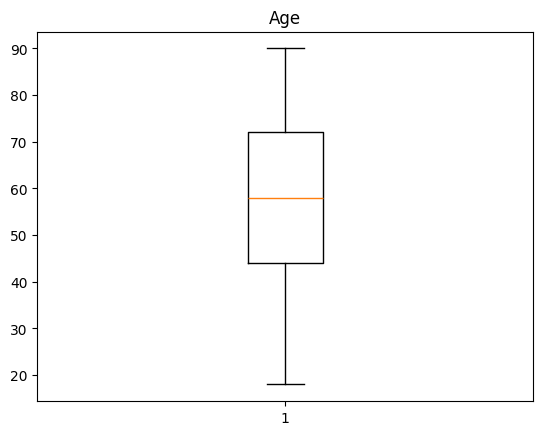

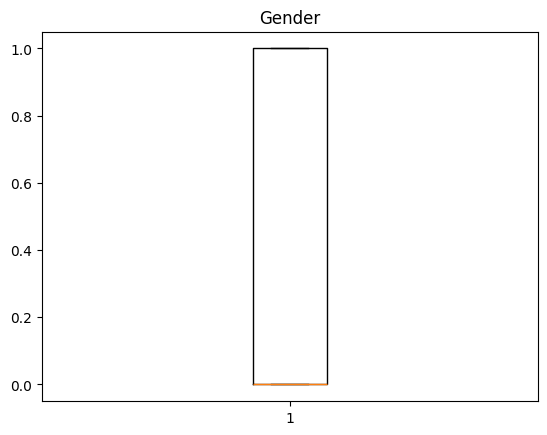

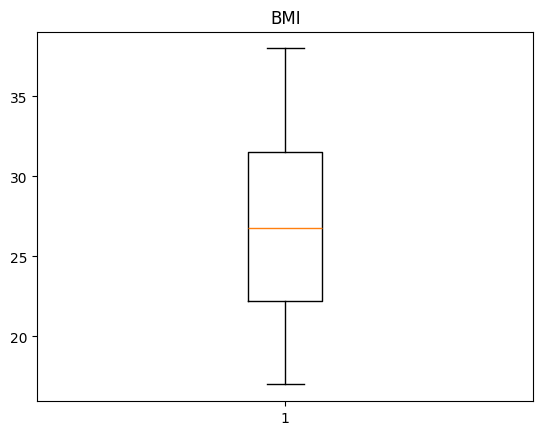

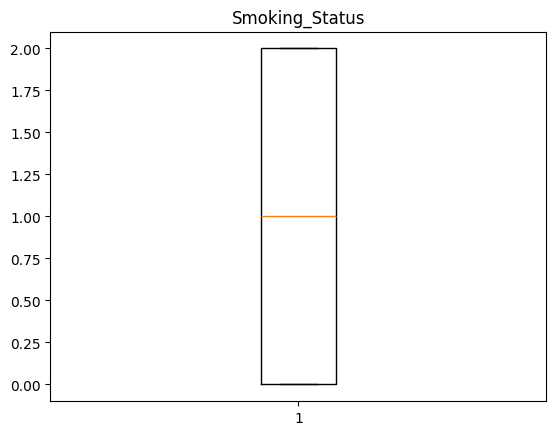

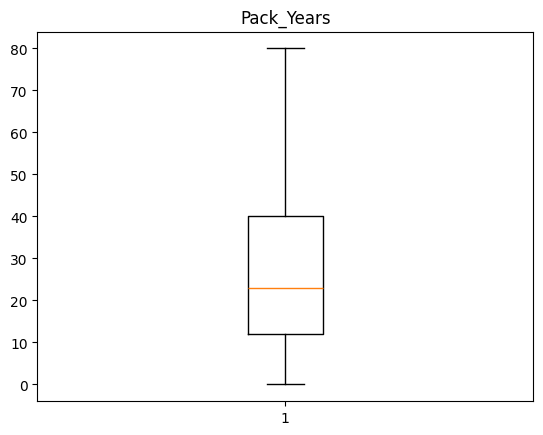

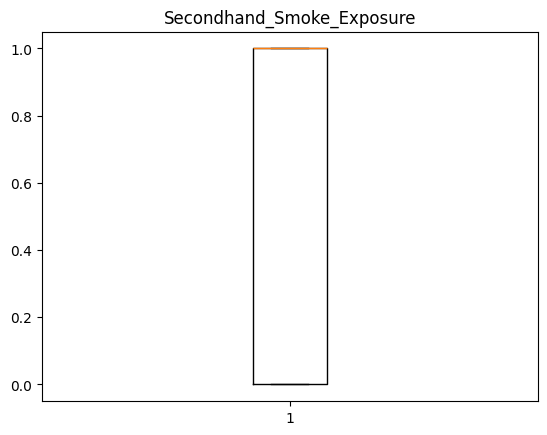

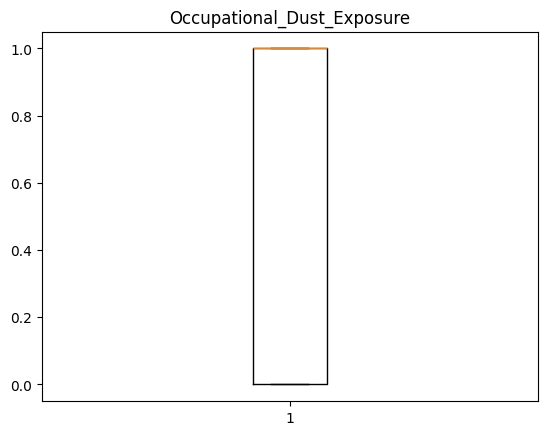

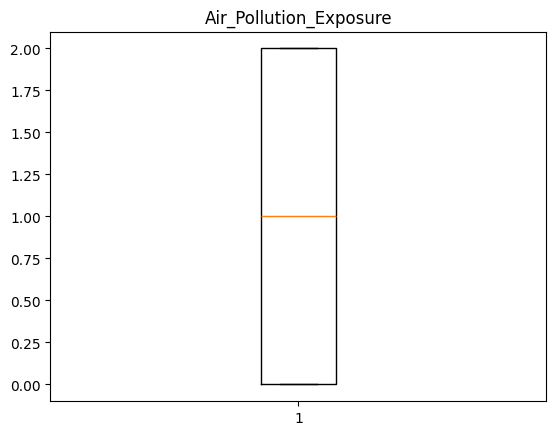

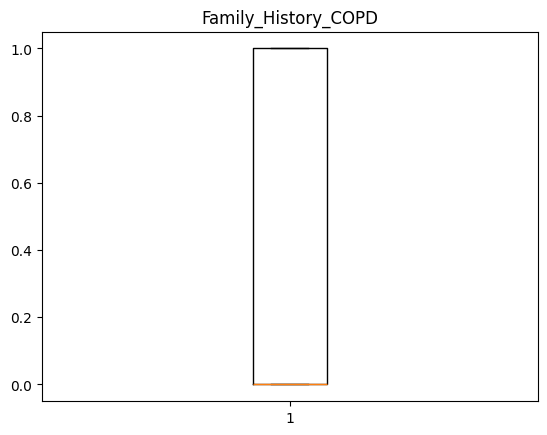

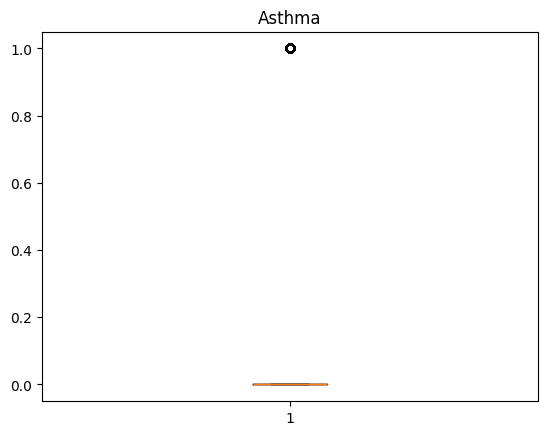

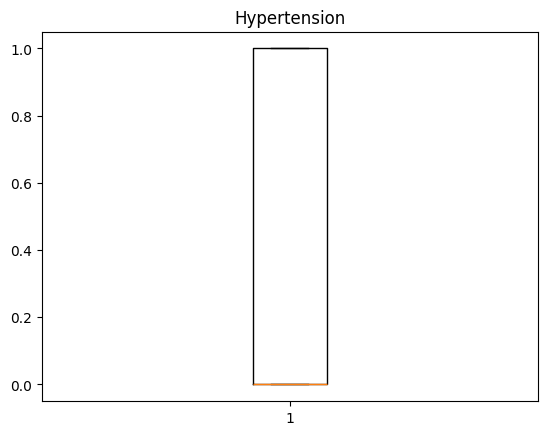

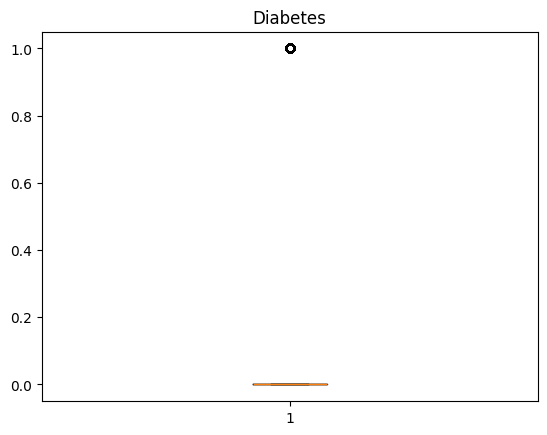

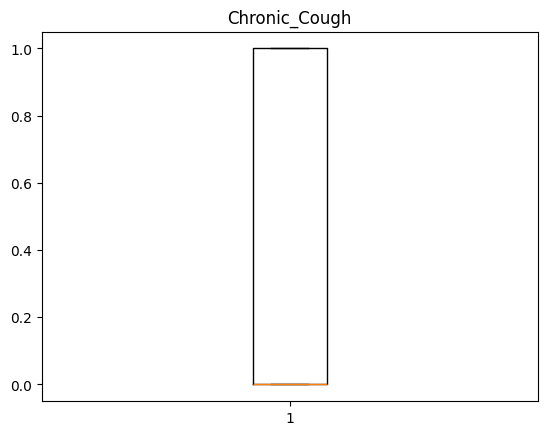

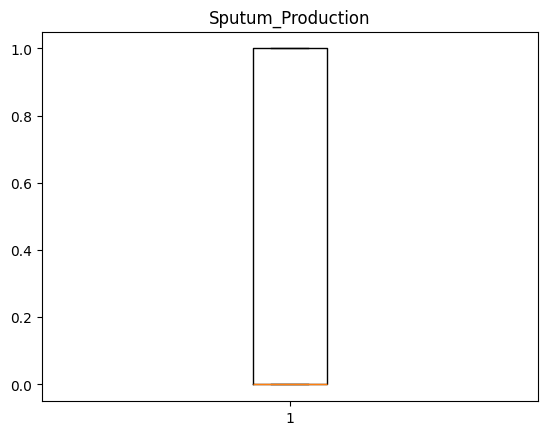

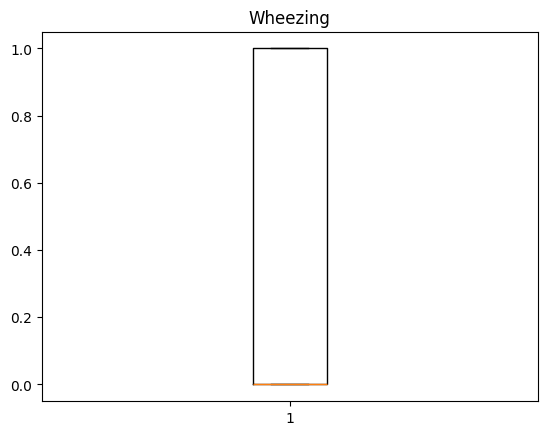

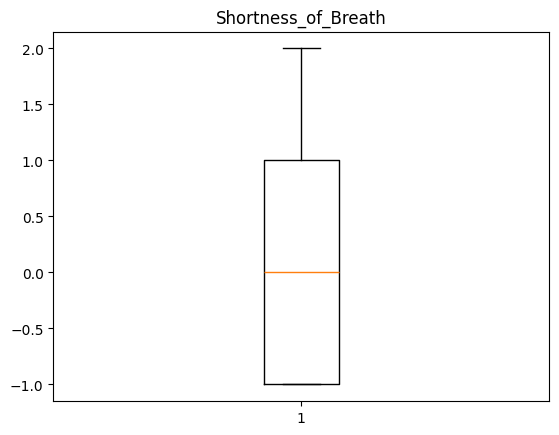

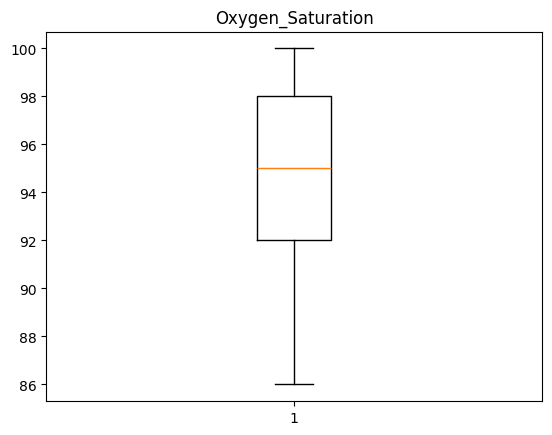

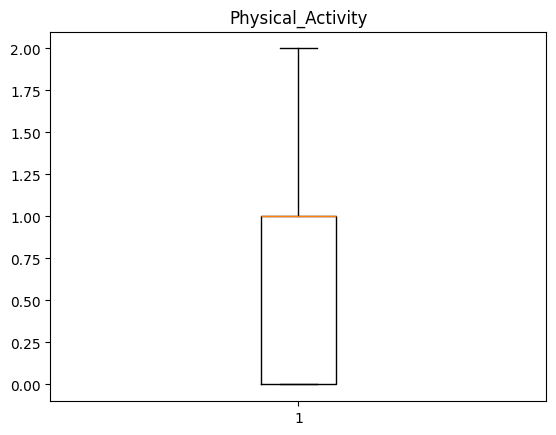

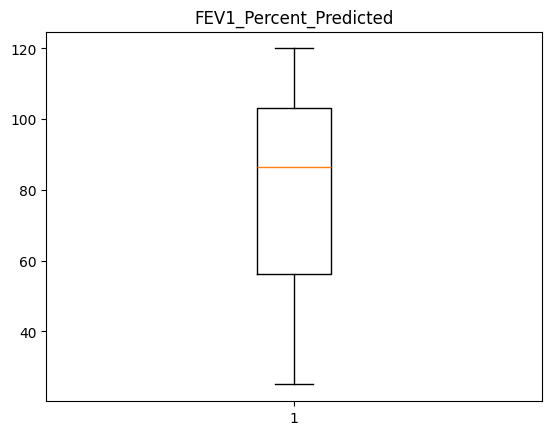

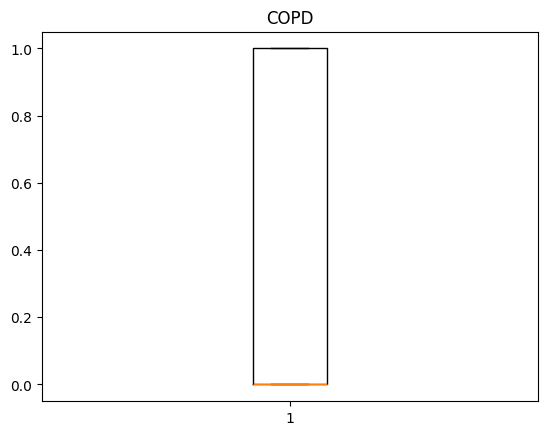

In [11]:
for col in df.columns:
    plt.title(col)
    plt.boxplot(df[col])
    plt.show()

In [12]:
df.corr()

,Age,Gender,BMI,Smoking_Status,Pack_Years,Secondhand_Smoke_Exposure,Occupational_Dust_Exposure,Air_Pollution_Exposure,Family_History_COPD,Asthma,Hypertension,Diabetes,Chronic_Cough,Sputum_Production,Wheezing,Shortness_of_Breath,Oxygen_Saturation,Physical_Activity,FEV1_Percent_Predicted,COPD
Age,1.000000,0.000636,-0.105488,0.201168,0.370156,0.001804,0.005616,0.206115,-0.002432,0.173565,0.117750,0.062565,0.331195,0.287349,0.298911,0.322426,-0.403416,-0.182441,-0.427246,0.482322
Gender,0.000636,1.000000,-0.004494,0.001470,0.004945,-0.002780,0.002692,0.000035,0.000939,0.003319,0.003895,0.005340,0.006664,0.005786,0.004452,0.006880,-0.003813,-0.004949,-0.005199,0.006320
BMI,-0.105488,-0.004494,1.000000,-0.090587,-0.165084,-0.001216,-0.002202,-0.096416,0.003760,-0.070951,-0.054272,-0.032139,-0.145278,-0.134458,-0.136003,-0.147212,0.186589,0.076539,0.195072,-0.218324
Smoking_Status,0.201168,0.001470,-0.090587,1.000000,0.375993,0.001491,0.002834,0.182547,-0.003013,0.139556,0.099837,0.053783,0.278035,0.249881,0.257213,0.271404,-0.346282,-0.162201,-0.363873,0.413016
Pack_Years,0.370156,0.004945,-0.165084,0.375993,1.000000,0.002736,-0.002341,0.326801,-0.005552,0.264973,0.187109,0.104428,0.517093,0.458841,0.470524,0.505134,-0.633701,-0.296008,-0.674695,0.759461
Secondhand_Smoke_Exposure,0.001804,-0.002780,-0.001216,0.001491,0.002736,1.000000,0.001738,-0.000723,0.001266,-0.004981,-0.006974,-0.000577,-0.002050,0.003501,-0.000706,0.000274,0.002238,-0.004126,-0.002268,-0.000588
Occupational_Dust_Exposure,0.005616,0.002692,-0.002202,0.002834,-0.002341,0.001738,1.000000,0.000500,0.003867,0.001525,0.001935,-0.006526,0.001697,-0.001074,-0.003788,0.000409,0.000763,0.009521,0.006016,-0.004458
Air_Pollution_Exposure,0.206115,0.000035,-0.096416,0.182547,0.326801,-0.000723,0.000500,1.000000,0.003285,0.148987,0.101835,0.057427,0.296421,0.256220,0.267618,0.287012,-0.358824,-0.171457,-0.381567,0.429364
Family_History_COPD,-0.002432,0.000939,0.003760,-0.003013,-0.005552,0.001266,0.003867,0.003285,1.000000,-0.009236,0.003706,0.003847,-0.005888,-0.000987,-0.000074,0.001679,0.002001,0.000973,0.005285,-0.003609
Asthma,0.173565,0.003319,-0.070951,0.139556,0.264973,-0.004981,0.001525,0.148987,-0.009236,1.000000,0.084673,0.036676,0.238862,0.210501,0.213971,0.230219,-0.285953,-0.132628,-0.303941,0.342273


<function matplotlib.pyplot.show(close=None, block=None)>

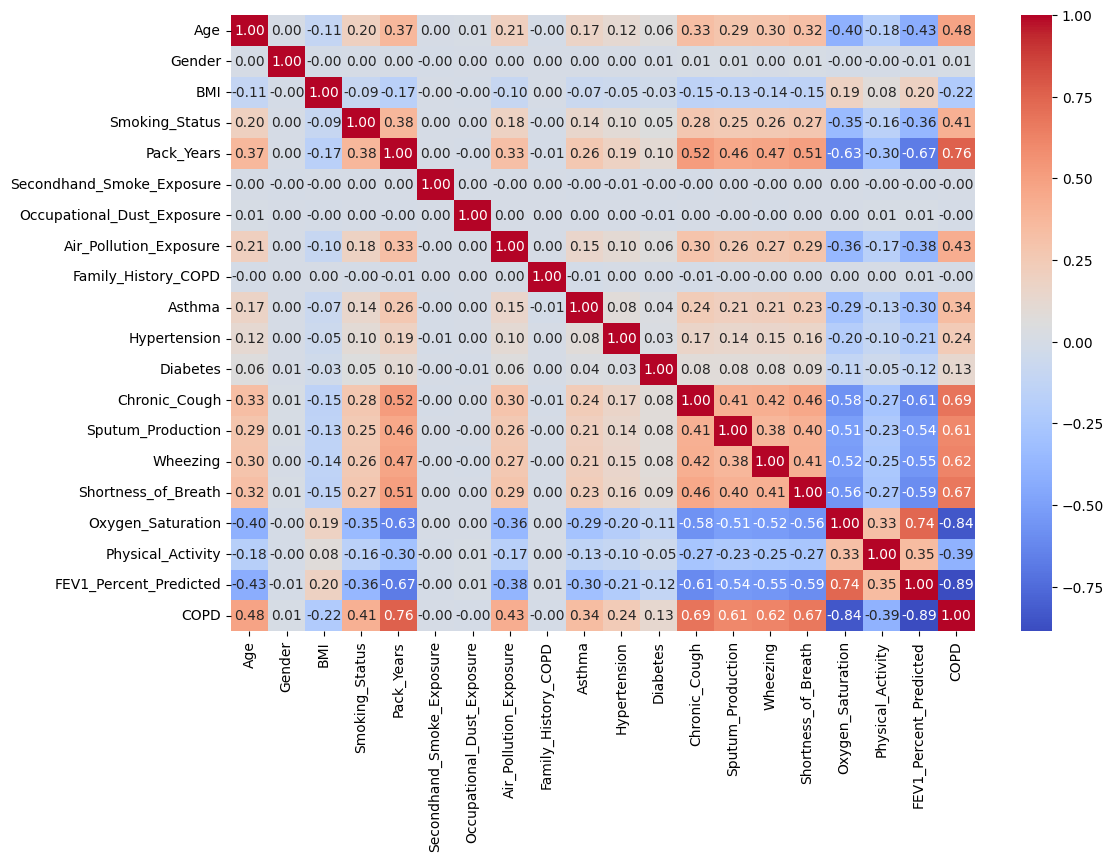

In [13]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),annot= True,cmap="coolwarm",fmt=".2f")
plt.show

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
x = df.drop("COPD",axis=1)
y = df['COPD']
x

,Age,Gender,BMI,Smoking_Status,Pack_Years,Secondhand_Smoke_Exposure,Occupational_Dust_Exposure,Air_Pollution_Exposure,Family_History_COPD,Asthma,Hypertension,Diabetes,Chronic_Cough,Sputum_Production,Wheezing,Shortness_of_Breath,Oxygen_Saturation,Physical_Activity,FEV1_Percent_Predicted
0,85,1,17.4,1,34,1,1,2,1,0,1,1,1,1,1,2,94,0,47.5
1,62,1,29.9,1,47,0,0,1,0,1,1,0,1,1,1,1,87,2,43.9
2,80,0,31.1,2,75,0,1,2,1,0,0,0,0,0,1,1,91,0,42.8
3,87,0,28.9,2,24,1,1,1,0,1,0,0,1,1,0,0,86,1,45.1
4,49,1,32.5,2,65,0,1,2,0,0,0,1,1,0,1,2,92,1,45.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,31,0,35.8,0,15,0,1,0,1,0,1,0,0,0,0,-1,99,0,115.6
49996,53,1,32.7,0,30,1,0,1,0,0,0,0,0,1,0,-1,96,0,110.4
49997,55,0,30.0,0,19,1,0,2,0,0,0,0,0,0,0,0,99,2,92.0
49998,72,1,30.8,0,2,0,0,1,0,0,0,0,0,0,0,1,99,2,113.4


In [16]:
y.value_counts(normalize=True)

COPD
0    0.6
1    0.4
Name: proportion, dtype: float64

In [17]:
x_train,x_test,y_train,y_test = train_test_split(x,y,stratify=y,random_state=42,test_size=0.2)

In [18]:
tree = DecisionTreeClassifier(min_samples_split=5)
tree.fit(x_train,y_train)
pred = tree.predict(x_test)
print(classification_report(y_test,pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      6000
           1       1.00      1.00      1.00      4000

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000



In [19]:
confusion_matrix(y_test,pred)

array([[6000,    0],
       [   0, 4000]])

In [20]:
train = tree.predict(x_train)
print(classification_report(y_train,train))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     24000
           1       1.00      1.00      1.00     16000

    accuracy                           1.00     40000
   macro avg       1.00      1.00      1.00     40000
weighted avg       1.00      1.00      1.00     40000



In [21]:
dump(tree,"Copd.joblib")

['Copd.joblib']